In [1]:
from adjoint import *
import numpy as np
import matplotlib.pyplot as plt

font = {"size": 24}

plt.rc("font", **font)

In [2]:
path = "base/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_5e-11_delta_1_tol_0.01_sg_0_order_0.txt"
params = initialize_variables_from_file(path)
dirname = (path.split("/")[-1])[:-4]
path = "runs/" + dirname

In [ ]:
def lens_prop(k, phi_I, T_R2K, T_K2R, zF, zm, wavelength=1e-6):
    k0 = 2 * np.pi / wavelength
    #     fT_i=prop(phi_I,k,k0,zI,T_R2K,T_K2R)
    phi_R0 = phi_I * np.exp(1j * k0 * zm)

    fT_f = propagate(phi_R0, k, k0, zF, T_R2K, T_K2R)

    return fT_f


In [3]:
f = 0.185  # focal length of lens
ell = 0  # order of Bessel J function
del_zg=0.03 

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f / (2 * fn)  # initial spot size
rmax = 0.0275  # the max value of r`
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
# dz = params["dz"]
# nzf = params["nzf"]
# fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]  # weighting function in r

In [4]:
def create_axiparabola(f0,del_zg,R,r):
    sag = 1/(4*f0)*r**2 - del_zg/(8*f0**2*R**2)*r**4 + \
        del_zg*(R**2+8*f0*del_zg)/(96*f0**4*R**4)*r**6
    return sag

In [5]:
# Hankel
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

In [6]:
f+del_zg

0.215

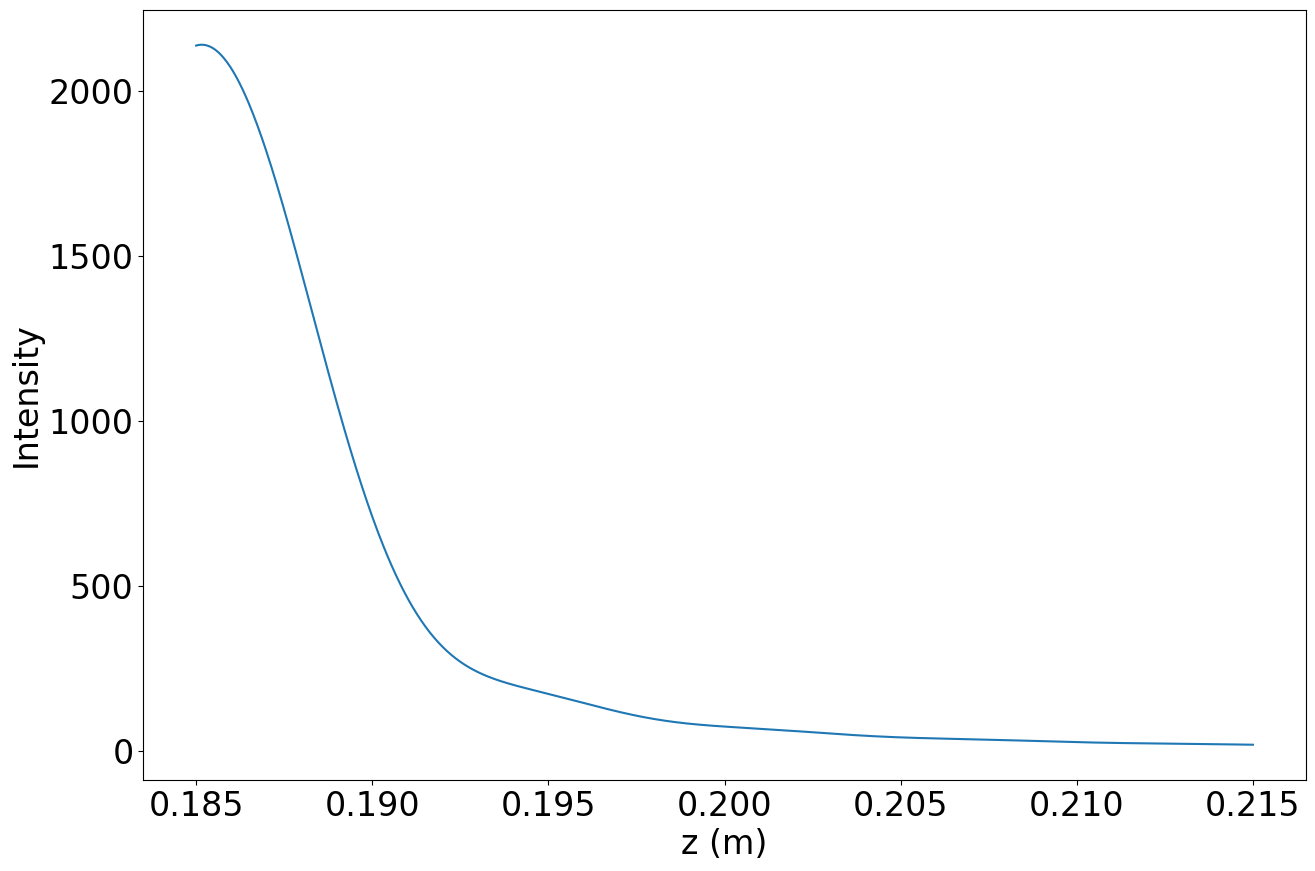

In [12]:
phi_I = 1j * np.exp(-((r / w0) ** 2))
zm_t=create_axiparabola(f,del_zg,rmax,r)
zF = np.linspace(0.185, 0.215, 1000)

ftf_t = lens_prop(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_t
)  # Target profile defined using target mirror
plt.figure(figsize=(15,10))
plt.plot(zF, 0.5*np.abs(ftf_t[0, :])**2)
# plt.axvline(x=zm_t[-1], color="r", linestyle="--", label="Target Mirror")
plt.xlabel("z (m)")
plt.ylabel("Intensity")
# plt.xlim([0, 0.01])
# plt.legend()
plt.savefig("axiparabola_adjoint.png")

plt.show()
